#### Setup

In [1]:
import os, shutil, subprocess, sys, textwrap
from pathlib import Path

from IPython.display import SVG, display

from dvc_dat import Dat
from dvc_dat.ledger import Ledger, Ref, Unlocked, bump

demos_path = Path(globals().get("demos_path", Path.cwd()))   # survives the chdir into the Dats project
os.chdir(demos_path)
scratch_path = demos_path / "scratch/api-walkthrough"
shutil.rmtree(scratch_path, ignore_errors=True)   # a re-run starts clean
for module_name in [m for m in sys.modules
                    if m.split(".")[0] in ("geometry", "plane", "mymodule")]:
    del sys.modules[module_name]                  # the modules the parts write into scratch
sys.path[:] = [p for p in sys.path if not p.startswith(str(scratch_path))]
scratch_path.mkdir(parents=True)

demo_game_path = str(demos_path / "demo_game")
if demo_game_path not in sys.path:
    sys.path.insert(0, demo_game_path)            # the Video class
os.environ["DAT_KEPT"] = str(scratch_path / "kept")   # where v.seal() records local seals
os.environ["PATH"] = f"{Path(sys.executable).parent}:{os.environ['PATH']}"   # `just run` execs this venv's python3
Dat.manager = None                                # the dat world reloads from this folder
git_cmd = ["git", "-c", "user.name=demo", "-c", "user.email=demo@example.com"]


def git_commit(message, *paths, cwd=None):
    """Stage the paths (default: everything) and commit; a re-run of a cell whose change is already committed is a no-op."""
    subprocess.run(git_cmd + ["add", "-A", "--", *(paths or ("."))], cwd=cwd, check=True)
    if subprocess.run(git_cmd + ["diff", "--cached", "--quiet"], cwd=cwd).returncode:
        subprocess.run(git_cmd + ["commit", "-q", "-m", message], cwd=cwd, check=True)


dats_project_path = scratch_path / "q-dats"       # the Dats project; its folder and pyproject name it q-dats


def show(name):
    """The figure `<name>.svg` beside this notebook."""
    display(SVG(filename=str(demos_path / f"{name}.svg")))


def show_file(path):
    """A file's contents under its path, each line behind `  | `, then a blank line."""
    path = Path(path)
    print(f"file: {path.relative_to(scratch_path)}")
    for line in path.read_text().splitlines():
        print(f"  | {line}")
    print()

# Triples

The ledger is a quad store: every fact is a row
`(rev, subject, predicate, object)`, every write is one
transaction, and every read is a view of one revision. The quick
tour: write, fold, one and many, `[]`, the triple reads, then the
ledger's own settings.

## A ledger and a transaction

In [2]:
L = Ledger(scratch_path / "ledger", create=True)

with L.transaction(by="human:dan", why="season opener") as t:
    t.add("game/G1", "home", "G4")
    t.add("game/G1", "away", "G5")
    t.add("game/G1", "court", "north")
rev1 = t.rev
print("rev1 id, court:", rev1.id, rev1.get("game/G1", "court"))   # 1 north

rev1 id, court: 1 north


`by` is required; `why` and any other keyword are rows on the
transaction's own subject. The `with` block commits one revision.

## A second transaction, and folding

A read folds the rows at or before its revision into the state
they mean: on an undeclared predicate the latest add wins.

In [3]:
with L.transaction(by="human:dan") as t:
    t.add("game/G1", "court", "south")
rev2 = t.rev
print("rev2 court:", rev2.get("game/G1", "court"))   # south: the latest add
print("rev1 court:", rev1.get("game/G1", "court"))   # north: rev1 never changes
print("history:", *rev2.history("game/G1", "court"), sep="\n")   # both rows are still stored
# history:
# <Row game/G1 court north rev=1 +>
# <Row game/G1 court south rev=2 +>

rev2 court: south
rev1 court: north
history:
<Row game/G1 court north rev=1 +>
<Row game/G1 court south rev=2 +>


## One and many

A predicate is `one` unless declared `many`. Declare `officials`
many, then write both kinds in one transaction: the `one`
predicate replaces, the `many` one accumulates.

In [4]:
with L.transaction(by="human:dan") as t:
    t.add("db/pred/officials", "db/cardinality", "many")
    t.add("game/G1", "court", "east")       # one: replaces south
    t.add("game/G1", "officials", "kim")    # many: accumulates
    t.add("game/G1", "officials", "ortiz")
rev3 = t.rev
print("rev3 court:", rev3.get("game/G1", "court"))           # east
print("rev3 officials:", rev3.all("game/G1", "officials"))   # ['kim', 'ortiz']
print("rev1 court, officials:", rev1.get("game/G1", "court"),
      rev1.all("game/G1", "officials"))                        # north []: looking back

rev3 court: east
rev3 officials: ['kim', 'ortiz']
rev1 court, officials: north []


The declaration is itself a row, on `db/pred/officials`. Any
earlier revision still reads as it did: `L.at(n)` is revision `n`.

## The `[]` accessor

Two keys read or assign one predicate; one key reads a subject's
record as a dict. `t.update(s, {...})` writes a record, an add per
key.

In [5]:
with L.transaction(by="human:dan") as t:
    t["game/G1", "court"] = "west"                       # one predicate: an add
    t.update("game/G2", {"home": "G1", "away": "G3",     # a record: an add per key
                         "officials": ["lee", "park"]})  # a list under a many key adds each
rev = t.rev
print("court:", rev["game/G1", "court"])   # west
print("game/G2:", rev["game/G2"])
# {'home': 'G1', 'away': 'G3', 'officials': ['lee', 'park']}

court: west
game/G2: {'home': 'G1', 'away': 'G3', 'officials': ['lee', 'park']}


`rev[s, p]` on a `many` predicate raises and names `all`; a
missing fact is a `KeyError`.

`t.update` reads nothing and retracts nothing: a key it omits
stays. `db/` keys go in as `add` takes them.

In [6]:
with L.transaction(by="human:dan") as t:
    t.update("game/G2", {"court": "north"})      # one add; the rest stays
print("game/G2:", t.rev["game/G2"])
#   game/G2: {'home': 'G1', 'away': 'G3',
#    'officials': ['lee', 'park'], 'court': 'north'}

game/G2: {'home': 'G1', 'away': 'G3', 'officials': ['lee', 'park'], 'court': 'north'}


Assigning a whole record, `t[s] = {...}`, makes the rows equal to
the dict and reads first, so it waits for "Locking the ledger"
below.

## Reading triple data

In [7]:
with L.transaction(by="human:dan") as t:
    t.remove("game/G1", "officials", "kim")   # a remove is a row too
rev = t.rev
print("score:", rev.get("game/G1", "score", default="tbd"))   # tbd: no raise
print("has home G4:", ("game/G1", "home", "G4") in rev)      # True
print("G1 officials:", rev.all("game/G1", "officials"))      # ['ortiz']
print("G2 officials:", rev.all("game/G2", "officials"))      # ['lee', 'park']
print("G2:", rev.all("game/G2"))                             # one position fixed: its (predicate, object) pairs
#   [('home', 'G1'), ('away', 'G3'), ('officials', 'lee'), ('officials', 'park'), ('court', 'north')]
print("courts:", rev.all("game/*", "court"))                 # a glob subject: (subject, object) pairs
#   [('game/G1', 'west'), ('game/G2', 'north')]
print("history:", *rev.history("game/G1", "officials"), sep="\n")   # the unfolded history, removes included
# history:
# <Row game/G1 officials kim rev=3 +>
# <Row game/G1 officials ortiz rev=3 +>
# <Row game/G1 officials kim rev=6 ->
print("court, per game:", rev.select(("court",), s="game/*"))   # keys=("court",): one tuple per game, its court
#   [('west',), ('north',)]
print("home and away, west court:", rev.select(("home", "away"), court="west"))   # keys=("home", "away"), filter court=west
#   [('G4', 'G5')]

score: tbd
has home G4: True
G1 officials: ['ortiz']
G2 officials: ['lee', 'park']
G2: [('home', 'G1'), ('away', 'G3'), ('officials', 'lee'), ('officials', 'park'), ('court', 'north')]
courts: [('game/G1', 'west'), ('game/G2', 'north')]
history:
<Row game/G1 officials kim rev=3 +>
<Row game/G1 officials ortiz rev=3 +>
<Row game/G1 officials kim rev=6 ->
court, per game: [('west',), ('north',)]
home and away, west court: [('G4', 'G5')]


`get` is one match of an exact pattern: `[]` with a default
instead of `KeyError`. `all` is every match as a list, binding the
open positions: with two fixed the objects, with one the
(predicate, object) pairs. A `*` at the end of the subject, allowed
on `all` and `refs` only, binds the subject too. `in` tests one
triple. `history` is the same pattern unfolded: every row with its
`+` or `-`, an add or a remove. `select(keys, **preds)` is SQL's
`SELECT keys WHERE preds`: the tuple names the predicates that come
back, in that order, one tuple per matching subject; the keywords
are the filter, `s="game/*"` a filter on the subject.

## Declaring an index

In [8]:
with L.transaction(by="human:dan") as t:
    t.add("db/pred/home", "db/index", "true")

An index is storage only: queries on `home` answer the same,
faster.

## Naming a revision

A revision is named by a row on the ledger's own subject, `db`.

### By version

In [9]:
with L.transaction(by="human:dan") as t:
    t.add("db", "db/version", "0.1.0")            # the ledger's version: a row on db
print(f"written at rev {t.rev.id}; L.at('0.1.0') is rev {L.at('0.1.0').id}, court {L.at('0.1.0')['game/G1', 'court']}")
# written at rev 8; L.at('0.1.0') is rev 8, court west

written at rev 8; L.at('0.1.0') is rev 8, court west


`(db, db/version, M.m.p)` names the revision its transaction
commits, and `L.at("M.m.p")` reads through the row to it. `bump`,
under "Locking the ledger", advances the version row for you.

### By tag

In [10]:
with L.transaction(by="human:dan") as t:
    t.add("db", "db/tag", "2026-Q4-official")     # a tag: another row on db
print(f"written at rev {t.rev.id}; L.at('2026-Q4-official') is rev {L.at('2026-Q4-official').id}")
# written at rev 9; L.at('2026-Q4-official') is rev 9

written at rev 9; L.at('2026-Q4-official') is rev 9


`(db, db/tag, name)` names the revision the same way, and
`L.at(name)` is that revision.

## Typing a predicate

In [11]:
with L.transaction(by="human:dan") as t:
    t.add("db/pred/date", "db/type", "str")
try:
    with L.transaction(by="human:dan") as t:
        t.add("game/G1", "date", {"y": 2026, "m": 10})
except TypeError as e:
    print("TypeError:", e)   # json under a str predicate: not written

TypeError: 'date' is declared db/type 'str'; 'game/G1' was given json:'{"m":10,"y":2026}'; nothing written


## Locking the ledger

Locking lets a transaction read the immediately preceding
revision, so a read-then-write builds on current data and no other
writer lands between.

The lock is the store's own write lock: SQLite `BEGIN IMMEDIATE`,
Postgres `SELECT … FOR UPDATE` on the one `ledger_lock` row. It
holds across threads, processes and machines. `lock=10` is the
budget to get the lock and run the body; past it the body is
interrupted and nothing is written. An unlocked transaction takes
the lock only at commit, for the write itself.

A transaction reads the previous revision and writes the next;
its own writes are not seen until it closes. So a body reads with
`t[s]`, alters, and writes back. `t[s] = {...}` makes the rows
equal to the dict, retracting what it omits, so it reads first.
Here one more official joins `game/G2`.

In [12]:
with L.transaction(by="human:dan", lock=10) as t:
    g2 = t["game/G2"]                              # the record immediately before this transaction
    t["game/G2"] = {**g2, "officials": g2["officials"] + ["vance"]}   # one more, written back
print("officials:", t.rev.all("game/G2", "officials"))

officials: ['lee', 'park', 'vance']


`bump(t, subject, part)` is the read-then-write a version row
needs: it reads `subject db/version` through `t.previous_rev` and
adds the next. Minor and major need `confirm=`. Here the ledger's
own clock, then a schema's.

In [13]:
with L.transaction(by="human:dan", lock=10) as t:
    print("db:", bump(t, "db", "minor", confirm=lambda old, new: True))                   # 0.1.0 -> 0.2.0
    print("schema/tape:", bump(t, "schema/tape", "minor", confirm=lambda old, new: True)) # none -> 0.1.0
print("L.at('0.2.0') id:", L.at("0.2.0").id)   # 12

db: 0.2.0
schema/tape: 0.1.0
L.at('0.2.0') id: 12


`t[s]` reads `t.previous_rev`, the top as it stands while the
body holds the write lock. Without `lock=` there is no
well-defined previous revision; notice the ledger refuses the read.

In [14]:
try:
    with L.transaction(by="human:dan") as t:       # no lock=
        t["game/G2"]
except Unlocked as e:
    print("Unlocked:", e)

Unlocked: the transaction is not locked: previous_rev is the top only under lock=


`bump`, `t[s] = {...}` and `del` read through `t.previous_rev` and
take `lock=`; `t[s, p] = o`, `t.update` and `t.add` read nothing
and need none.

In [15]:
with L.transaction(by="human:dan") as t:           # no lock=: nothing is read
    t["game/G2", "court"] = "east"                 # an add on a one predicate
    t.add("game/G2", "officials", "wu")            # an add on a many predicate
print("game/G2:", t.rev["game/G2"])

game/G2: {'home': 'G1', 'away': 'G3', 'officials': ['lee', 'park', 'vance', 'wu'], 'court': 'east'}


# Values

A value is a Python object stored in the ledger by its content: its
hash is its subject, and once stored it never changes. The quick
tour: store and name a value, find it by its preds, compute values
with ledger functions, and let the ledger remember their results.

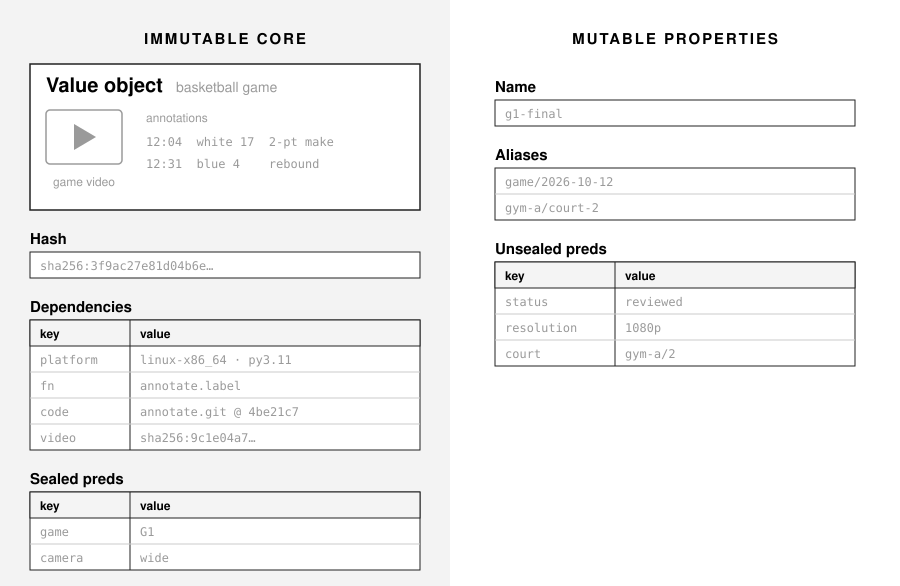

In [16]:
show("api-walkthrough-values")   # black: the parts every value has; gray: an example

## Value objects

A value's class is a `Value` subclass in a module (here
`demo_game/game.py`), saying how the object becomes bytes and back,
and which preds (searchable string rows) it carries:

```python
@ledger_class(preds=("game", "camera", "span"))
class Video(Value):
    def __init__(self, frames: bytes):
        self.frames = frames
    def encode(self) -> bytes:
        return self.frames
    @classmethod
    def decode(cls, data: bytes, store) -> "Video":
        return cls(data)
```

### Storing a value, with its name

In [17]:
from demo_game.game import Video

# create a new value
video_value = Video(b"G1 wide camera, 9000 frames")
# add preds to the value
video_value.preds.update(game="G1", camera="wide")
# save the value under its name
with L.transaction(by="human:dan") as t:
    video_subject = video_value.seal(t, name="video/G1")

print("video:", repr(video_value))           # → video: <Video video/G1>
print("subject:", video_subject)             # → the sha256 of the content, 64 hex chars

video: <Video video/G1>
subject: 66d16043c075dcee8c3598e34f2eb7037dfea8e446ef0c89e3c9e4b209c320c4


`seal` stores the value and names it in one step. After the seal
the value, its preds included, is frozen.

### Referring to it: by name or by hash

In [18]:
rev1 = L.at()
by_name_video = rev1.load("video/G1")
by_hash_video = rev1.load(video_subject)
print("loaded by name:", by_name_video.frames)   # → b'G1 wide camera, 9000 frames'
print("same value by hash:", by_name_video.subject == by_hash_video.subject)   # → True
video_ref = Ref(rev1, "video/G1")
print("ref:", repr(video_ref))                        # → <Ref video/G1>
print("its preds:", video_ref.preds)                  # → {'game': 'G1', 'camera': 'wide'}
print("loaded from the ref:", video_ref.load().frames)   # → b'G1 wide camera, 9000 frames'

loaded by name: b'G1 wide camera, 9000 frames'
same value by hash: True
ref: <Ref video/G1>
its preds: {'game': 'G1', 'camera': 'wide'}
loaded from the ref: b'G1 wide camera, 9000 frames'


`load` fetches the value. A `Ref` is the subject without its bytes:
its rows are readable (`preds`, `aliases`, `name`) and `load()`
fetches the value when wanted. The finders come in both forms,
`values` and `refs`.

### Assigning preds, and finding values by them

Preds set before the seal are written with it, as rows on the
value's subject.

In [19]:
# create a second value, add its preds, save it under its name
g2_video = Video(b"G2 wide camera, 8400 frames")
g2_video.preds.update(game="G2", camera="wide")
with L.transaction(by="human:dan") as t:
    g2_subject = g2_video.seal(t, name="video/G2")

rev2 = L.at()
print("camera=wide:", rev2.values(camera="wide"))           # → [<Video video/G1>, <Video video/G2>]
print("game=G1, camera=wide:", repr(rev2.value(game="G1", camera="wide")))   # → <Video video/G1>
print("every Video:", rev2.refs(kind=Video))                # → [<Ref video/G1>, <Ref video/G2>]

camera=wide: [<Video video/G1>, <Video video/G2>]
game=G1, camera=wide: <Video video/G1>
every Video: [<Ref video/G1>, <Ref video/G2>]


`values` loads every match, `value` exactly one, `refs` the
matches unloaded. The preds the class declares are sealed with the
value and never change; any other pred is a row beside it, written
or updated in a later transaction, and the finders follow it.

### Updating a value's name and alias

A name is a `db/alias` row pointing at the value's subject. Any
number may point at one value; its name is the alias written
latest, and removing the row takes a name away.

In [20]:
with L.transaction(by="human:dan") as t:
    t.add("raw/G1/wide-camera", "db/alias", video_subject)   # a second alias for video/G1
    t.add("game/G2/baseline", "db/alias", g2_subject)        # video/G2 renamed: the new alias in,
    t.remove("video/G2", "db/alias", g2_subject)             # the old one out
g1_ref, g2_ref = Ref(L.at(), video_subject), Ref(L.at(), g2_subject)
print("G1 aliases:", sorted(g1_ref.aliases), " name:", g1_ref.name)   # → ['raw/G1/wide-camera', 'video/G1']  raw/G1/wide-camera
print("G2 aliases:", g2_ref.aliases, " name:", g2_ref.name)            # → ['game/G2/baseline']  game/G2/baseline

G1 aliases: ['raw/G1/wide-camera', 'video/G1']  name: raw/G1/wide-camera
G2 aliases: ['game/G2/baseline']  name: game/G2/baseline


## Ledger functions

A ledger function is a Python function the ledger knows by dotted
name; it takes the revision first, and its result is sealed as a
value. It lives in a git repository, so the ledger can record
exactly which code ran.

### Set up repo and code

One git repository, `geometry-app`, holds two packages and both
functions used below: `geometry.main.distance` runs in this process;
`plane.measure.length` runs sandboxed. Each package declares its
version in its `__init__.py`; `geometry` is the app, so its version
is the app's.

In [21]:
# setup: create the repo in a folder, with these source files, and commit them
repo_path = scratch_path / "geometry-app"
for package in ("geometry", "plane"):
    (repo_path / package).mkdir(parents=True, exist_ok=True)
(repo_path / ".gitignore").write_text("__pycache__/\n")
(repo_path / "geometry/__init__.py").write_text('''\
__version__ = "5.3.9"
''')

(repo_path / "geometry/main.py").write_text('''\
import math
from dvc_dat.ledger import ledger_fn

@ledger_fn
def distance(rev, a, b) -> float:
    dx, dy = b[0] - a[0], b[1] - a[1]
    print(f"ran: sqrt({dx}² + {dy}²) = {math.dist(a, b)}")
    return math.dist(a, b)
''')

(repo_path / "plane/__init__.py").write_text('''\
__version__ = "2.7.1"
''')

(repo_path / "plane/measure.py").write_text('''\
import math
from dvc_dat.ledger import ledger_fn

@ledger_fn
def length(rev, a, b) -> float:
    return math.dist(a, b) * 0.5     # metres per unit
''')

subprocess.run(git_cmd + ["init", "-q"], cwd=repo_path, check=True)
git_commit("geometry and plane", cwd=repo_path)

sys.path.insert(0, str(repo_path))

### The ledger namespace

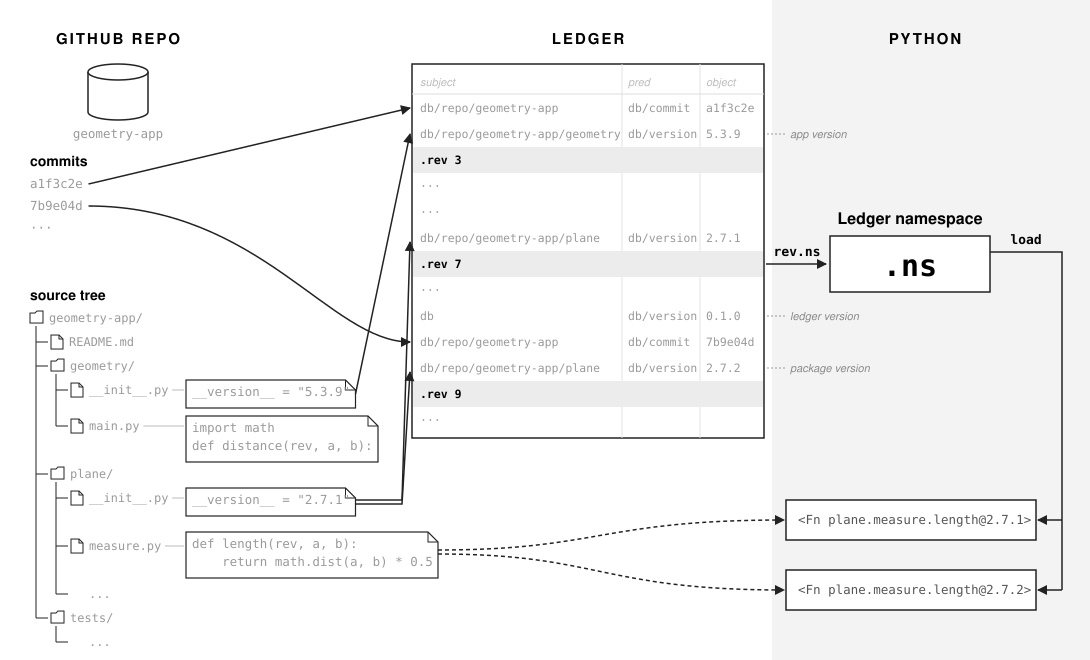

In [22]:
show("api-walkthrough-ns")

The ledger namespace, `ns`, is the bridge between the ledger and
Python: Python's namespace, modules, functions and objects by dotted
name, on the ledger, so every name has a history of revisions tied
to the git commit history of its code. `rev.ns` is the namespace at
a revision; `t.ns` is the namespace at a transaction, reading the
revision before it.

`ns.load(name)` is the object a dotted name denotes.
`ns.name_of(obj)` is the dotted name `load` takes back to an object.

In [23]:
ns = L.at().ns
dist_fn = ns.load("math.dist")
print("loaded:", dist_fn)                   # → loaded: <built-in function dist>
print("its name:", ns.name_of(dist_fn))     # → its name: math.dist

loaded: <built-in function dist>
its name: math.dist


`math.dist` is the standard library's. An unmounted name resolves
in this process, the interpreter running this notebook, as `import`
would. So does `geometry.main.distance` below, from the checkout
put on `sys.path` under "Set up repo and code"; such a function's
code is the whole checkout at its commit.

### Accessing and using Python functions

In [24]:
show_file(repo_path / "geometry/__init__.py")
show_file(repo_path / "geometry/main.py")
distance_fn = L.at().ns.load("geometry.main.distance")
print("fn:", repr(distance_fn), " code:", repr(distance_fn.code))
# → fn: <Fn geometry.main.distance@5.3.9>  code: <Code geometry@5.3.9>
hypotenuse_value = distance_fn(a=(0, 0), b=(3, 4))
print("result:", hypotenuse_value.obj, " sealed at:", hypotenuse_value.sealed)
# → result: 5.0  sealed at: <the seal's moment>
print("db/repo/geometry-app/geometry:", L.at()["db/repo/geometry-app/geometry"])
# → db/repo/geometry-app/geometry: {'db/version': '5.3.9'}
print("db/repo/geometry-app:", L.at()["db/repo/geometry-app"])
# → db/repo/geometry-app: {'db/commit': '<the commit>'}

file: geometry-app/geometry/__init__.py
  | __version__ = "5.3.9"

file: geometry-app/geometry/main.py
  | import math
  | from dvc_dat.ledger import ledger_fn
  | 
  | @ledger_fn
  | def distance(rev, a, b) -> float:
  |     dx, dy = b[0] - a[0], b[1] - a[1]
  |     print(f"ran: sqrt({dx}² + {dy}²) = {math.dist(a, b)}")
  |     return math.dist(a, b)



fn: <Fn geometry.main.distance@5.3.9>  code: <Code geometry@5.3.9>


ran: sqrt(3² + 4²) = 5.0
result: 5.0  sealed at: 2026-10-31T02:00:40Z
db/repo/geometry-app/geometry: {'db/version': '5.3.9'}
db/repo/geometry-app: {'db/commit': 'ef7cf57fb708bae77dffa20f06734d57976923dc'}


`L.at().ns.load(name)` is what a dotted name denotes on the ledger;
for a function, an `Fn`. Calling it runs it and seals the
plain `float` it returns as a value (`.obj` unboxes it). A
function's repr is `<Fn name@version>`; `code` is the code it
is loaded from, the package `geometry` at the version it declares.

A repo is one git checkout and has one commit; it can hold several
packages, each with its own `__version__`. So the commit is a
`db/commit` row on `db/repo/<repo>` and each package's version a
`db/version` row on `db/repo/<repo>/<package>`; the ledger writes
both, so both predicates carry `db/`. Here the repo `geometry-app` holds
the packages `geometry` and `plane`. This first clean run wrote both rows.

### Sandboxed functions

`t.ns.mount(at, root=, repo=)` puts the repo's folder `plane`
under the name `plane`: two `db/mount/plane` rows; `ns.mounts()` is
the mount table at a revision. A name under a mount loads in a
sandbox, a fresh interpreter holding only that folder. Its version
is the mounted package's `__version__`; the checksum of the files
it loaded is its identity.

In [25]:
with L.transaction(by="human:dan") as t:
    t.ns.mount("plane", root="plane", repo="geometry-app")   # the two db/mount/plane rows
print("mounts:", L.at().ns.mounts())
# → mounts: {'plane': {'root': 'plane', 'repo': 'geometry-app'}}
show_file(repo_path / "plane/__init__.py")
show_file(repo_path / "plane/measure.py")

mounts: {'plane': {'root': 'plane', 'repo': 'geometry-app'}}
file: geometry-app/plane/__init__.py
  | __version__ = "2.7.1"

file: geometry-app/plane/measure.py
  | import math
  | from dvc_dat.ledger import ledger_fn
  | 
  | @ledger_fn
  | def length(rev, a, b) -> float:
  |     return math.dist(a, b) * 0.5     # metres per unit



In [26]:
length_fn = L.at().ns.load("plane.measure.length")
segment_value = length_fn(a=(0, 0), b=(3, 4))
print("fn:", repr(length_fn), " code:", repr(length_fn.code), " sandboxed:", length_fn.code.sandboxed)
# → fn: <Fn plane.measure.length@2.7.1>  code: <Code plane@2.7.1>  sandboxed: True
print("result:", segment_value.obj)                 # → result: 2.5
print("geometry db/version:", L.at()["db/repo/geometry-app/geometry", "db/version"])   # → geometry db/version: 5.3.9
print("plane db/version:", L.at()["db/repo/geometry-app/plane", "db/version"])         # → plane db/version: 2.7.1

fn: <Fn plane.measure.length@2.7.1>  code: <Code plane@2.7.1>  sandboxed: True
result: 2.5
geometry db/version: 5.3.9
plane db/version: 2.7.1


`geometry` and `plane` share one checkout, the repo `geometry-app`, and each package keeps its own version clock, written by its first clean run.

#### A sandbox is a snapshot of the code

Loading a sandboxed function takes a snapshot of the code it runs;
`code` is that snapshot, the sandbox: `modules` are the files in
it, `version` the name the package gives it. The function is looked
up by name inside it, and the version it shows is the snapshot's.
Only the snapshot has identity, `subject` `db/code/<16 hex>`; a
result names it and the function in it apart, as `code` and `fn`,
and the snapshot records every module the run loaded
(`plane/__init__.py` too).

In [27]:
sandbox = length_fn.code
print("sandbox:", repr(sandbox), " version:", sandbox.version, " modules:", sandbox.modules)
# → sandbox: <Code plane@2.7.1>  version: 2.7.1  modules: ['plane/__init__.py', 'plane/measure.py']
print("result's code:", segment_value.dependencies["code"], " is the sandbox:",
      segment_value.dependencies["code"] == sandbox.subject)
# → result's code: db/code/1fa8b8c101e51d7a  is the sandbox: True
print("result's fn:", segment_value.dependencies["fn"])
# → result's fn: plane.measure.length

sandbox: <Code plane@2.7.1>  version: 2.7.1  modules: ['plane/__init__.py', 'plane/measure.py']
result's code: db/code/1fa8b8c101e51d7a  is the sandbox: True
result's fn: plane.measure.length


Change the code, and bump the version with it, and the snapshot is
a new one. The old result still names the snapshot that made it.

In [28]:
measure_path = repo_path / "plane/measure.py"
measure_path.write_text(measure_path.read_text().replace("* 0.5 ", "* 0.25"))
(repo_path / "plane/__init__.py").write_text('__version__ = "2.7.2"\n')
git_commit("quarter metres", cwd=repo_path)
new_length_fn = L.at().ns.load("plane.measure.length")
print("new fn:", repr(new_length_fn), " sandbox:", repr(new_length_fn.code))
# → new fn: <Fn plane.measure.length@2.7.2>  sandbox: <Code plane@2.7.2>
print("new result:", new_length_fn(a=(0, 0), b=(3, 4)).obj)    # → new result: 1.25
print("old result's code:", segment_value.dependencies["code"], " fn:", segment_value.dependencies["fn"],
      " holds:", segment_value.obj)
# → old result's code: db/code/1fa8b8c101e51d7a  fn: plane.measure.length  holds: 2.5

new fn: <Fn plane.measure.length@2.7.2>  sandbox: <Code plane@2.7.2>


new result: 1.25
old result's code: db/code/1fa8b8c101e51d7a  fn: plane.measure.length  holds: 2.5


## Ledger evaluation

`rev.run(name, **keys)` is a lookup and a call, traced: the result
records what it depended on, and is remembered, so asking again is
answered from the ledger. `distance` prints a `ran:` line when it
runs: once below.

In [29]:
far_value = L.at().run("geometry.main.distance", a=(0, 0), b=(6, 8))
# → ran: sqrt(6² + 8²) = 10.0
print("result:", far_value.obj)                       # → result: 10.0

again_value = L.at().run("geometry.main.distance", a=(0, 0), b=(6, 8))   # no ran: line: a hit
print("same value:", again_value.subject == far_value.subject)           # → same value: True

ran: sqrt(6² + 8²) = 10.0
result: 10.0


same value: True


### Splitting the run method into discrete actions

`run` is three separable steps: load the function, run it with its
provenance captured, put the result on the ledger. `seal=False`
stops after the second, so the result can be looked at first;
`.seal(t)` is the third. Nothing runs twice.

In [30]:
distance_fn = L.at().ns.load("geometry.main.distance")                   # (1) load the function
print("fn:", repr(distance_fn))                                     # → fn: <Fn geometry.main.distance@5.3.9>
draft_value = distance_fn(a=(0, 0), b=(9, 12), seal=False)          # (2) run it, provenance captured, nothing kept
print("draft:", draft_value.obj, " sealed:", draft_value.sealed)    # → 15.0 None
with L.transaction(by="human:dan", why="keep it") as t:             # (3) put it on the ledger
    draft_value.seal(t)
kept_value = L.at().run("geometry.main.distance", a=(0, 0), b=(9, 12))   # the same call: a hit
print("hit:", kept_value.subject == draft_value.subject)            # → True: nothing ran

fn: <Fn geometry.main.distance@5.3.9>


ran: sqrt(9² + 12²) = 15.0
draft: 15.0  sealed: None


hit: True


`seal=` says how far a call goes: `"get"` only looks, `False` runs
and keeps nothing, `True` also seals the result on this machine, a
ledger or a transaction saves it there. Left out, it saves to the
function's own ledger, as `run` does.

## Provenance

A value a ledger function returns records what it depended on: the
function at its version, the code's commit, the platform, and every
name and value it read. That record is its provenance.

### What a result depends on

In [31]:
for dep_key, dep_value in sorted(far_value.dependencies.items()):
    print(f"{dep_key[:28]:30}= {dep_value[:56]}")

code                          = db/code/590ae8cd3d282e48
code/geometry-app             = 8b8a1d21
fn                            = geometry.main.distance
platform                      = darwin-arm64-py3.12
platform/record               = {"card":null,"cpu":"Apple M2 Max","cuda":null,"driver":n


- `code/geometry-app`: the commit of the repo `geometry-app` the function
  ran at.
- `code`: the snapshot of the code the function ran from, by its
  subject; here the package `geometry` at its version, as for the
  sandbox above.
- `fn`: the function's dotted name inside that snapshot.
- `platform`, `platform/record`: the operating system, CPU and
  Python version it ran on, as a tag and as a record, not a file.

A name the function read, and the value it pointed at, is a row
here too; `matches(rev)` is whether every row still holds.

### Sealing a value by hand

Sealing fixes a value: its bytes' hash and its preds, so it can be
checked but not changed. Saving puts the sealed value on the
ledger's timeline. `v.seal(t)` does both at once; here they are
apart.

In [32]:
highlight_video = Video(b"G1 highlights, 600 frames")                 # 1. make a value
highlight_video.preds.update(game="G1", camera="wide")

print("sealed, hash:", highlight_video.seal()[:12])                   # 2. seal it, on this machine only
print("sealed at:", highlight_video.sealed)                           # → <the seal's moment>
try:
    highlight_video.preds["camera"] = "baseline"
except Exception as error:
    print("change refused:", type(error).__name__, error)             # → TypeError cannot modify a sealed value's preds
print("G1 videos on the ledger:", L.at().values(game="G1"))           # not on the timeline yet

with L.transaction(by="human:dan", why="keep the highlights") as t:   # 3. keep it
    highlight_video.seal(t, name="video/G1/highlights")
print("G1 videos on the ledger:", L.at().values(game="G1"))           # now it is

sealed, hash: 75b825dc06c0
sealed at: 2026-10-31T02:00:43Z
change refused: TypeError cannot modify a sealed value's preds
G1 videos on the ledger: [<Video raw/G1/wide-camera>]
G1 videos on the ledger: [<Video raw/G1/wide-camera>, <Video video/G1/highlights>]


# Dats

A dat is a handle for a folder of arbitrary data, derived from and
specified by a recursive dictionary of parameters: its spec. On a
ledger it is also a value: sealed, loaded, memoized, found.

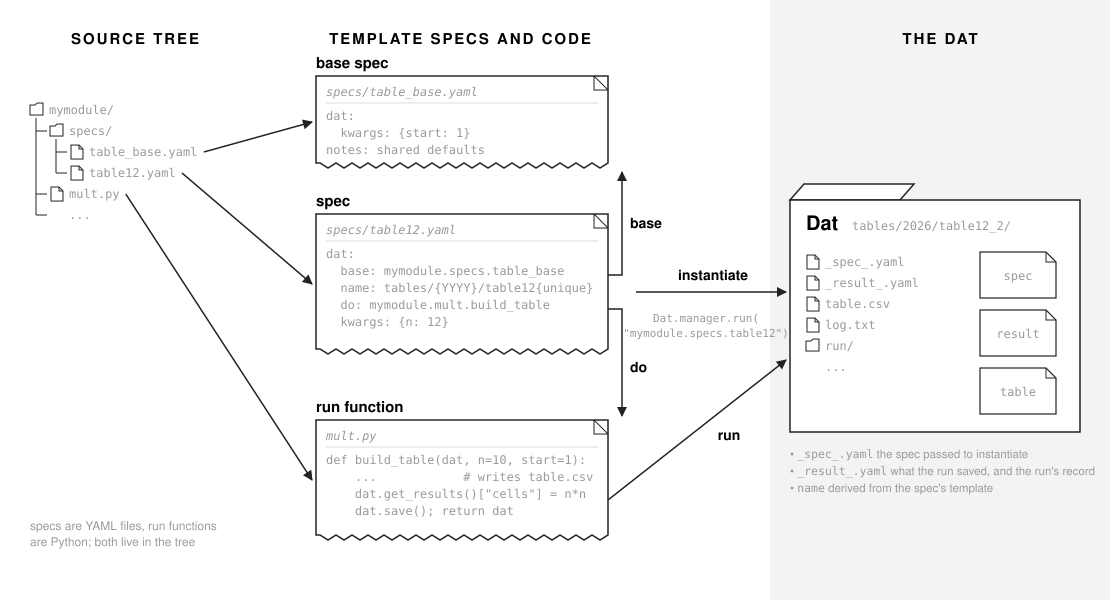

In [33]:
show("api-walkthrough-dats")

#### Project setup

The Dats part works in its own project, a git checkout named `q-dats` whose `.datconfig.yaml` makes it a plain dat project, its dats in `data/`; `mymodule` holds a run function and two template specs.

In [34]:
dats_project_path.mkdir(parents=True, exist_ok=True)
os.chdir(dats_project_path)
Path(".gitignore").write_text(".dat/\ndata/\n")
Path("pyproject.toml").write_text('[project]\nname = "q-dats"\nversion = "0.1.0"\n')
subprocess.run(git_cmd + ["init", "-q"], check=True)
git_commit("q-dats")
sys.path.insert(0, str(dats_project_path))
Path(".datconfig.yaml").write_text("dat_folders: data\n")   # a plain dat project: its dats live in data/
Dat.manager = None                   # the dat world reloads from this folder

In [35]:
# the files: a run function in mult.py, two template specs in specs/
module_path = Path("mymodule")
(module_path / "specs").mkdir(parents=True)
(module_path / "__init__.py").write_text('__version__ = "0.1.0"\n')   # the code's version, in its source
(module_path / "mult.py").write_text('''\
import csv
from pathlib import Path


def write_table(folder, n=10, start=1):
    """`table.csv`, the n x n multiplication table from `start`; its cell count."""
    numbers = range(start, start + n)
    with open(Path(folder, "table.csv"), "w", newline="") as f:
        csv.writer(f).writerows([[a * b for b in numbers] for a in numbers])
    return n * n


def build_table(dat, n=10, start=1):
    """The run function: `Dat.manager.run` calls it with the new dat and the spec's kwargs."""
    cells = write_table(dat.get_path(), n, start)
    Path(dat.get_path(), "log.txt").write_text(f"{n} x {n} from {start}\\n")
    dat.get_results()["cells"] = cells
    dat.save()
    return dat
''')
(module_path / "specs/table_base.yaml").write_text('''\
dat:
  kwargs: {start: 1}
notes: shared defaults
''')
(module_path / "specs/table12.yaml").write_text('''\
dat:
  base: mymodule.specs.table_base
  name: tables/{YYYY}/table12{unique}
  do: mymodule.mult.build_table
  kwargs: {n: 12}
''')
git_commit("mymodule", "mymodule")   # only the module: .datconfig.yaml stays untracked, so its later edits leave the checkout clean
Dat.ns.mount(folder="mymodule", at="mymodule")   # mymodule's files join the dat world's namespace:
# mymodule/specs/table12.yaml answers to mymodule.specs.table12, build_table in mult.py to mymodule.mult.build_table



A spec's `dat:` part is what the dat system reads: `do:` names the
run function, `kwargs:` its arguments, `base:` a spec to inherit,
`name:` a folder template; above, `table12` inherits `table_base`.

## Dat creation

A dat is created in three steps:

1. **Look up** its spec by name: `Dat.ns.load(name)` is the object
   a dotted name names, here the spec file's dict as written.
2. **Expand** it: `Dat.manager.expand_spec(spec)` merges the spec
   over its `dat.base`, which it drops, then fills every template
   variable `{}`; `{YYYY}` is the year, `{unique}` empty.
3. **Instantiate** it: `Dat.create(spec=expanded_spec)` is the Dat
   object, its folder made and `_spec_.yaml` written. Nothing runs.

In [36]:
spec = Dat.ns.load("mymodule.specs.table12")    # 1. the spec as written
expanded_spec = Dat.manager.expand_spec(spec)   # 2. dat.base merged in, every {…} filled
table12_dat = Dat.create(spec=expanded_spec)    # 3. the Dat and its folder

In [37]:
# print results
table12_path = Path(table12_dat.get_path())
print("SPEC:    ", spec)
print("EXPANDED:", expanded_spec)   # base: gone, kwargs gains start, notes appears, name: filled
print("DAT:     ", repr(table12_dat))
print("FILES:   ", sorted(os.listdir(table12_path)))
print("_SPEC_.YAML:\n" + textwrap.indent((table12_path / "_spec_.yaml").read_text(), "    "))
# _spec_.yaml: the expanded spec, plus kind: dvc_dat.core.Dat

SPEC:     {'dat': {'base': 'mymodule.specs.table_base', 'name': 'tables/{YYYY}/table12{unique}', 'do': 'mymodule.mult.build_table', 'kwargs': {'n': 12}}}
EXPANDED: {'dat': {'kwargs': {'start': 1, 'n': 12}, 'name': 'tables/2026/table12', 'do': 'mymodule.mult.build_table'}, 'notes': 'shared defaults'}
DAT:      <Dat: tables/2026/table12>
FILES:    ['_spec_.yaml']
_SPEC_.YAML:
    dat:
      kwargs:
        start: 1
        n: 12
      name: tables/2026/table12
      do: mymodule.mult.build_table
      kind: dvc_dat.core.Dat
    notes: shared defaults



## `Dat.create`, the three steps in one call

`Dat.create(spec=name)` is the shorthand: it looks the spec up,
expands it (base merged, `{}` filled) and instantiates the dat.
Nothing runs.

In [38]:
shorthand_dat = Dat.create(spec="mymodule.specs.table12")   # steps 1-3

In [39]:
# print results
shorthand_path = Path(shorthand_dat.get_path())
print("DAT:", repr(shorthand_dat))
print("MANUAL _SPEC_.YAML:\n" + textwrap.indent((table12_path / "_spec_.yaml").read_text(), "    "))
print("SHORTHAND _SPEC_.YAML:\n" + textwrap.indent((shorthand_path / "_spec_.yaml").read_text(), "    "))
# the same kwargs, do, kind and notes; name: tables/2026/table12 by hand, tables/{YYYY}/table12{unique} in the shorthand

DAT: <Dat: tables/2026/table12_2>
MANUAL _SPEC_.YAML:
    dat:
      kwargs:
        start: 1
        n: 12
      name: tables/2026/table12
      do: mymodule.mult.build_table
      kind: dvc_dat.core.Dat
    notes: shared defaults

SHORTHAND _SPEC_.YAML:
    dat:
      kwargs:
        start: 1
        n: 12
      name: tables/{YYYY}/table12{unique}
      do: mymodule.mult.build_table
      kind: dvc_dat.core.Dat
    notes: shared defaults



One difference, in `name:`. The shorthand expands `{}` after it
places the folder, with the placement's own `{YYYY}` and `{unique}`:
`table12` is taken, so `{unique}` counts up to `_2`, and
`_spec_.yaml` keeps `name:` as the template. By hand,
`expand_spec` sees no folder, so `{unique}` is always empty and
`name:` is filled once; were `tables/2026/table12` taken, step 3
would raise `FileExistsError` instead of counting up.

## Running a dat

`Dat.manager.run(dat)` is the one way to run a dat: it calls the
spec's run function with the dat and the spec's kwargs, in place,
and records the run in `dat.run`. `save()` in the run function
seals the folder, its results in `_result_.yaml`.
The cell runs once: a sealed dat refuses a second run, which
`RuntimeError: ... is sealed` reports.

In [40]:
Dat.manager.run(table12_dat)   # calls build_table in mult.py with this dat and n=12, start=1

<Dat: tables/2026/table12>

In [41]:
# print results
print("FILES:", sorted(os.listdir(table12_path)))
print("CELLS:", table12_dat.get_results()["cells"])
print("TABLE.CSV:\n" + textwrap.indent("\n".join((table12_path / "table.csv").read_text().splitlines()[:3]), "    "))
print("_RESULT_.YAML:\n" + textwrap.indent((table12_path / "_result_.yaml").read_text(), "    "))

FILES: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
CELLS: 144
TABLE.CSV:
    1,2,3,4,5,6,7,8,9,10,11,12
    2,4,6,8,10,12,14,16,18,20,22,24
    3,6,9,12,15,18,21,24,27,30,33,36
_RESULT_.YAML:
    dat:
      dependencies: {}
      standing: referenceable
      hash: functional
      sha256: sha256:4a1f195a93d4863c561b129b857351dd40ae67df33d6a9cab8bfb2f575be36dc
    cells: 144



`dat.run` is the run's record, a sub-dat in the dat's `run/`
folder: when and where it ran, on which commit, how long it took
and the hash it sealed. It is outside the dat's own hash.

In [42]:
run_results = table12_dat.run.get_results()["dat"]
print("run:", repr(table12_dat.run))   # run: <Dat: tables/2026/table12/run>
print("run_at:", run_results["run_at"])   # run_at: when the run started
print("run_time:", run_results["run_time"])   # run_time: how long build_table took
print("code:", run_results["code"])   # code: the branch, commit and dirty flag of the checkout holding mult.py

run: <Dat: tables/2026/table12/run>
run_at: 2026-10-30 19:00:44
run_time: 00:00:00.001
code: {'branch': 'main', 'commit': '4f4ca1af161b3bb8af95d271fe4444efe779c918', 'dirty': False}


Given a name, `Dat.manager.run` creates the dat from the spec
first: it returns what the run function returned, a new folder
every call.

In [43]:
again_dat = Dat.manager.run("mymodule.specs.table12")   # same as: Dat.manager.run(Dat.create(spec="mymodule.specs.table12"))
print("dat:", repr(again_dat))   # dat: <Dat: tables/2026/table12_3>
print("files:", sorted(os.listdir(again_dat.get_path())))
# files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']

dat: <Dat: tables/2026/table12_3>
files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']


## Running and storing a dat on the ledger

A ledger remembers: a run is a memo entry, found again rather than
rerun; a dat is a value, sealed under a name and loaded back; dats
are found by their preds.

`Ledger(create=True)` makes the ledger in this folder and adds
`ledger:` to `.datconfig.yaml`; the reloaded dat world names
through it. In a ledger project names come from the ledger's
mounts alone and `Dat.ns.mount` is refused, so `mymodule` is
mounted with `t.ns.mount`, which writes two `db/mount` rows; the
earlier mount went with the old world.

#### Setup

In [44]:
L = Ledger(create=True)              # .dat/ledger, and ledger: in .datconfig.yaml
Dat.manager = None                   # the dat world reloads, its namespace the ledger's
print(".datconfig.yaml:", Path(".datconfig.yaml").read_text().splitlines())
# → .datconfig.yaml: ['dat_folders: data', 'ledger: .dat/ledger']
import mymodule                      # discovery finds the checkout, the repo q-dats
with L.transaction(by="human:dan", why="mount mymodule") as t:
    t.ns.mount("mymodule", root="mymodule")   # the two db/mount rows: the folder, and the repo, by default this project's, q-dats
try:
    Dat.ns.mount(folder="mymodule", at="mymodule")
except TypeError as e:
    print("refused:", str(e).split(" (")[0])
# → refused: a ledger project names things through its db/mount rows

.datconfig.yaml: ['dat_folders: data', 'ledger: .dat/ledger']
refused: a ledger project names things through its db/mount rows


### Ledger run

`L.at().run(name)` is a run remembered on the ledger: the result
found if this code computed it before, else run and sealed as the
memo entry. One call creates the dat in the three steps, runs it,
and remembers it.

In [45]:
table12_value = L.at().run("mymodule.specs.table12")
print("ran:", repr(table12_value))   # ran: <Dat tables/2026/table12>: the spec's template, filled in the ledger's data folder

ran: <Dat tables/2026/table12>


#### What the run did, piece by piece

The run took the three creation steps, through the ledger's
mounts: `Dat.ns.load` read the spec off the mounted file, never
imported; `expand_spec` merged its base and filled its `{}`. The
expanded spec, `dat.name` removed and `dat.kind` set, is the memo
key, stored as the value's `db/keys`.

In [46]:
# print results
print("SPEC:    ", Dat.ns.load("mymodule.specs.table12"))
print("EXPANDED:", Dat.manager.expand_spec(Dat.ns.load("mymodule.specs.table12")))
print("DB/KEYS: ", L.at()[table12_value.subject, "db/keys"])   # the memo key

SPEC:     {'dat': {'base': 'mymodule.specs.table_base', 'name': 'tables/{YYYY}/table12{unique}', 'do': 'mymodule.mult.build_table', 'kwargs': {'n': 12}}}


EXPANDED: {'dat': {'kwargs': {'start': 1, 'n': 12}, 'name': 'tables/2026/table12', 'do': 'mymodule.mult.build_table'}, 'notes': 'shared defaults'}
DB/KEYS:  {'dat': {'do': 'mymodule.mult.build_table', 'kind': 'dvc_dat.core.Dat', 'kwargs': {'n': 12, 'start': 1}}, 'notes': 'shared defaults'}


The run function loads as an `Fn`, a ledger function: kind `dat`
(undecorated, run through a spec), sandboxed because it is
mounted. It ran in a sandboxed worker, its code the mounted files
it loaded; `db/fn` names it, and the first clean run wrote the
package's version clock, `db/repo/q-dats/mymodule` `db/version`.

In [47]:
# print results
run_fn = Dat.ns.load("mymodule.mult.build_table")
print("FN:         ", repr(run_fn), " kind:", run_fn.kind, " sandboxed:", run_fn.code.sandboxed)
print("DB/FN:      ", L.at()[table12_value.subject, "db/fn"])
print("DB/VERSION: ", L.at()["db/repo/q-dats/mymodule", "db/version"])   # db/repo/q-dats/mymodule

FN:          <Fn mymodule.mult.build_table@0.1.0>  kind: dat  sandboxed: True
DB/FN:       mymodule.mult.build_table
DB/VERSION:  0.1.0


The same spec asked again is a memo hit: nothing runs, nothing is
written.

In [48]:
top_id = L.at().id
again_value = L.at().run("mymodule.specs.table12")
print("hit:", again_value.subject == table12_value.subject,
      " nothing written:", L.at().id == top_id)   # hit: True  nothing written: True

hit: True  nothing written: True


### Storing a handmade dat on the ledger

On a ledger a dat is a value: sealed under a name, loaded back,
found by its preds. The hand-made `table12_dat` is sealed here; nothing
runs. Its preds are its spec's `kwargs` and its result's entries,
read from the folder.

In [49]:
with L.transaction(by="human:dan") as t:
    table12_dat.seal(t, name="table/12")   # the folder's files go to the art store; the row names the kind, dvc_dat.core.Dat
print("dat:", repr(table12_dat), " sealed:", table12_dat.sealed)   # dat: <Dat table/12>  sealed: <the seal's moment>

loaded_dat = L.at().load("table/12")       # the folder rebuilt from the store; nothing runs
print("files:", sorted(os.listdir(loaded_dat.get_path())))
# files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
print("cells:", loaded_dat.get_results()["cells"])   # cells: 144
print("preds:", dict(sorted(loaded_dat.preds.items())))
# preds: {'cells': '144', 'n': '12', 'start': '1'}

dat: <Dat table/12>  sealed: 2026-10-31T02:00:48Z
files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
cells: 144
preds: {'cells': '144', 'n': '12', 'start': '1'}


Sealing sent the files to the art store by their hashes; the
manifest naming them is the value's bytes. `load` rebuilds the
folder from the store, a view in the ledger's data folder; it does
not run anything.

### Finding dats

A dat on the ledger is found by its preds: its spec's kwargs and
its results. `values(kind=Dat, **preds)` is every dat whose preds
equal the given ones; `value(...)` the one dat, an error on none
or several; `select(keys, ...)` the matches as tuples of the
named preds. First, two more runs, n=5 and n=9, to find among.

In [50]:
for n in (5, 9):
    L.at().run("mymodule.specs.table12", n=n)   # kwargs update the spec's dat.kwargs, as with Dat.manager.run

In [51]:
# print results
print("ALL:     ", L.at().values(kind=Dat))
print("N=12:    ", L.at().values(kind=Dat, n=12))       # the run and the handmade table/12
print("CELLS=81:", repr(L.at().value(kind=Dat, cells=81)))   # exactly one: the n=9 run
print("N, CELLS:", L.at().select(("n", "cells"), kind=Dat))   # every dat, two preds each
print("N=5:     ", L.at().select(("cells",), kind=Dat, n=5))   # one pred of the n=5 dat

ALL:      [<Dat tables/2026/table12>, <Dat table/12>, <Dat tables/2026/table12_2>, <Dat tables/2026/table12_3>]
N=12:     [<Dat tables/2026/table12>, <Dat table/12>]
CELLS=81: <Dat tables/2026/table12_3>
N, CELLS: [('12', '144'), ('12', '144'), ('5', '25'), ('9', '81')]
N=5:      [('25',)]
